# Kilonova observations and extraction with X-shooter

This companion to `01_Kilonovae.ipynb` starts with a flat AB continuum control, then runs the same Kasen transient plus displaced host at 1.5, 7.5 and 20 rest-frame days. Both faint-continuum and higher-resolution X-shooter settings are simulated and reduced with the prototype DRP.

The two notebooks use the same evaluated dark-sky atmosphere at airmass 1.3, seeing .70 arcsec and MJD 60310.25. Telescope, slit, throughput, detector sampling and effective read noise remain instrument-specific. Prepared images contain accumulated electrons and explicit per-pixel variance, including an independently drawn blank exposure. Native ADU frames are saved separately.

Outputs go to `xshooter_kilonova_reduced/`; the earlier `xshooter_kilonova/` run is preserved. Flux-calibrated science includes host light. The transient-only reference is labeled accordingly; the flat AB control is the clean technical flux test.

The saved optical frames and executed outputs in this revision use ScopeSim `a0495f7`, before the separate ADC-ordering correction. The archived comparison is a baseline for that correction; rerunning with a newer ScopeSim revision generates a new optical realization.

In [1]:
from pathlib import Path
from copy import deepcopy
from time import perf_counter
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.io import fits
from astropy.time import Time
from astropy.visualization import simple_norm
from synphot.units import convert_flux
import scopesim as sim
import scopesim_templates as sim_tp
from scopesim.source.source_templates import ab_spectrum
from zs_scopesim_tools.helpers import configure_irdb_path, make_local_output_dir, set_scopesim_log_level, warning_prevent_sync_alt_ra_dec, disable_scopesim_progress_bars, electron_readouts, combine_readouts
from zs_scopesim_tools.comparison import detector_rates
from zs_scopesim_tools.sources import transient, kilonova_spectra, lamp_flat, _read_lamp_lines

irdb = Path(configure_irdb_path())
set_scopesim_log_level('error')
output_dir = make_local_output_dir('xshooter_kilonova_reduced')
ARMS = ('UVB', 'VIS', 'NIR')
MJD, AIRMASS, SEEING = 60310.25, 1.3, .70
timings, exposure_rows, peak_rows = [], [], []
print('Output:', output_dir)
print('ScopeSim:', sim.__file__)

Output: /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced
ScopeSim: /Users/jibailey/src/scopesim/scopesim/__init__.py


## Flat continuum first, then the science scene

The AB 20 point source is independent of the AB 16 calibration standard. The kilonova source adds the original AB 14 host at an across-slit offset of 10.5 arcsec. The host's extended wings still contribute near the transient; a scene/transient ratio is not a pure calibration residual.

In [2]:
flat_ab = sim_tp.misc.point_source(sed=ab_spectrum(mag=20))
standard = sim_tp.misc.point_source(sed=ab_spectrum(mag=16))
redshift = .0098
phases = (1.5, 7.5, 20.)
model_files = ['knova_d1_n10_m0.025_vk0.30_Xlan1e-4.0.h5', 'knova_d1_n10_m0.040_vk0.15_Xlan1e-1.5.h5']
host = sim_tp.galaxy(sed='brown/NGC3870', z=redshift, amplitude=14, pixel_scale=.01, r_eff=2.5, n=1., ellip=.3, theta=90, extend=5)
host.shift(dy=10.5*u.arcsec)
spectra = kilonova_spectra(model_files, phases=phases, redshift=redshift, combine_models=True)
science_sources = {'FLAT_AB': flat_ab}
for phase in phases:
    science_sources[f'KILONOVA_{phase:g}D'] = host + transient(x=0, y=0, spextrum_template=spectra[phase], name=f'KN {phase}d')
lamp = lamp_flat()
lamp_lines = _read_lamp_lines(irdb/'ZShooter_v2/lamp_lines')
domeflat = sim_tp.calibration.flat_field(temperature=3000*u.K, amplitude=8*u.ABmag, filter_curve='V', extend=60)
short_trace = sim_tp.calibration.flat_field(temperature=3000*u.K, amplitude=8*u.ABmag, filter_curve='V', extend=2)

## Configured exposures and common atmosphere

Faint continuum uses 1.0/.9/.9 arcsec slits with spectral CCD charge binning by two. Higher resolution uses .8/.9/.6 arcsec slits and unbinned CCDs. NIR is unbinned in both cases.

One hour on source uses 1800 s x 2 in UVB/VIS, 300 s x 12 in faint-mode NIR and 450 s x 8 in high-mode NIR. NDIT counts independent integrations/ramps, not samples up a ramp. X-shooter's native NIR product averages NDIT ramps; the helper converts that actual noisy product to an accumulated-electron image and propagates its variance. Each science object has its own independently drawn equal-time blank, so the estimator costs an additional hour of sky time before overheads. The 89,000-electron NIR linearity check applies to each integration; the final accumulated image can exceed that value.

The configured high-mode sky/thermal peak is 78,852 electrons per 450 s ramp, 11.4% below that limit. At the initially considered 600 s it would reach 105,136 electrons. Faint-mode science peaks at 53,843 electrons per 300 s. These are expected source plus optical-background counts before random draws, evaluated from the actual configured detector rates. Dark adds only 9 and 6 electrons per high/faint ramp, respectively. The adopted limit is an exposure check; the detector model does not simulate nonlinear saturation.

Calibration illumination is the same synthetic lamp/3000 K flat used for ZShooter. Per-arm calibration DIT targets 30,000 electrons at the brightest pixel with NDIT=1. The NIR noise table's minimum supported DIT is 1 s, so some calibration peaks exceed the target while remaining below the same linearity limit. Actual DITs and peaks are recorded below. This is a simulation calibration choice, not an ESO observing recommendation.

In [3]:
atmosphere_names = ('atmo_transmission', 'continuum_emission', 'airglow_and_interline_continuum')
common_commands = sim.UserCommands(use_instrument='ZShooter_v2', properties={'!OBS.mjdobs': MJD, '!OBS.airmass': AIRMASS, '!OBS.seeing': SEEING, '!OBS.brightness': 'dark', '!ATMO.skycalc_timeout': 60.})
warning_prevent_sync_alt_ra_dec(common_commands)
common_train = sim.OpticalTrain(common_commands)
common_atmosphere = [deepcopy(common_train[name]) for name in atmosphere_names]
del common_train
configurations = {
    'faint': {'!INST.uvb_curr_slit': '1.0', '!INST.vis_curr_slit': '0.9', '!INST.nir_curr_slit': '0.9', '!DET.biny_uvb': 2, '!DET.biny_vis': 2},
    'high': {'!INST.uvb_curr_slit': '0.8', '!INST.vis_curr_slit': '0.9', '!INST.nir_curr_slit': '0.6', '!DET.biny_uvb': 1, '!DET.biny_vis': 1},
}
trains, frame_files = {}, {}
calibration_disabled = (*atmosphere_names, 'seeing_psf', 'atmospheric_dispersion')
print('Common atmosphere:', [(effect.meta['name'], type(effect).__name__) for effect in common_atmosphere])

Common atmosphere: [('atmo_transmission', 'TAPASTERCurve'), ('continuum_emission', 'SkyBackgroundTERCurve'), ('airglow_and_interline_continuum', 'PalaceAirglowEmission')]


In [4]:
def observe(train, target, mode, label, disabled=()):
    flags = {name: train[name].include for name in disabled}
    for name in disabled:
        train[name].include = False
    for plane in train.image_planes:
        plane.data.fill(0)
    started = perf_counter()
    try:
        with disable_scopesim_progress_bars():
            train.observe(target, update=False)
    finally:
        for name, included in flags.items():
            train[name].include = included
    timings.append((mode, label, perf_counter()-started))
    print(mode, label, f'{timings[-1][2]:.1f} s', flush=True)

def exposure_settings(dits, ndits):
    settings = {'dit': dits[0], 'ndit': ndits[0]}
    for arm, dit, ndit in zip(ARMS, dits, ndits, strict=True):
        settings[f'dit_{arm.lower()}'] = dit
        settings[f'ndit_{arm.lower()}'] = ndit
    return settings

def save_readouts(readouts, directory, stem, object_name, imagetype):
    directory.mkdir(parents=True, exist_ok=True)
    paths = []
    for arm, hdul in zip(ARMS, readouts, strict=True):
        for header in (hdul[0].header, hdul[1].header):
            header['OBJECT'] = object_name
            header['IMAGETYPE'] = imagetype
            header['INSTRUME'] = 'XSHOOTER'
            header['ARM'] = arm
            header['MJD-OBS'] = MJD
            header['DATE-OBS'] = Time(MJD, format='mjd').isot
        path = directory/f'{stem}_{arm}.fits'
        hdul.writeto(path, overwrite=True)
        paths.append(path)
    return paths

def current_readout(train, settings, mode, directory, stem, object_name, roid):
    native = train.readout(roid=roid, **settings)
    save_readouts(native, directory/'native', stem, object_name, 'STANDARD_RAW' if object_name == 'STANDARD' else 'RAW_OBJECT')
    electrons = electron_readouts(train, native)
    for arm, hdul in zip(ARMS, electrons, strict=True):
        h = hdul[1].header
        exposure_rows.append((mode, stem, arm, h['DIT'], h['NDIT'], h['EXPTIME'], h['RON'], h['DARK']))
    del native
    return electrons

def subtract_saved_blank(electrons, blank_paths):
    blank = [fits.open(path, memmap=False) for path in blank_paths]
    prepared = combine_readouts([electrons, blank], [1, -1], source_indices=[0])
    for hdul in blank:
        hdul.close()
    return prepared

In [5]:
for mode, settings in configurations.items():
    directory = output_dir/mode
    directory.mkdir(parents=True, exist_ok=True)
    properties = {'!OBS.mjdobs': MJD, '!OBS.airmass': AIRMASS, '!OBS.seeing': SEEING, '!OBS.brightness': 'dark', '!SIM.random.seed': 62419, '!OBS.dit': 1., '!OBS.ndit': 1} | settings
    commands = sim.UserCommands(use_instrument='XSHOOTER', set_modes=['SPEC'], properties=properties, ignore_effects=['skycalc_atmosphere'])
    warning_prevent_sync_alt_ra_dec(commands)
    train = sim.OpticalTrain(commands)
    for effect in common_atmosphere:
        train.optics_manager.add_effect(deepcopy(effect))
    assert train['shot_noise'].include and train['readout_noise'].include
    trains[mode] = train
    frame_files[mode] = {'calibrations': {}, 'science': {}}
    caldir = directory/'calibrations'
    # Only the zero-exposure CCD readouts are retained as bias calibrations.
    observe(train, None, mode, 'bias', disabled=calibration_disabled)
    bias = current_readout(train, exposure_settings([0., 0., 1.], [1, 1, 1]), mode, caldir, 'bias', 'BIAS', 10)
    bias_paths = save_readouts(bias, caldir, 'bias', 'BIAS', 'BIAS')
    bias_paths.pop().unlink()  # The required one-second NIR read is not a bias calibration.
    frame_files[mode]['calibrations']['bias'] = bias_paths
    del bias
    for label, target in [('arc', lamp), ('flat', domeflat), ('trace', short_trace)]:
        observe(train, target, mode, label, disabled=calibration_disabled)
        rates = detector_rates(train)
        dits = [30000/image.max() for image in rates]
        dits[-1] = max(1., dits[-1])  # ESO NIR noise table starts at one second.
        for arm, dit, image in zip(ARMS, dits, rates, strict=True):
            peak_rows.append((mode, label, arm, dit, image.max()*dit))
        assert rates[-1].max()*dits[-1] < 89000, 'Dim the calibration source before the NIR minimum DIT saturates.'
        kind = {'arc': 'ARCS', 'flat': 'DOMEFLAT', 'trace': 'TRACE'}[label]
        electrons = current_readout(train, exposure_settings(dits, [1, 1, 1]), mode, caldir, label, label.upper(), {'arc': 11, 'flat': 12, 'trace': 13}[label])
        frame_files[mode]['calibrations'][label] = save_readouts(electrons, caldir, label, label.upper(), kind)
        del electrons, rates
    print('CALIBRATIONS READY', caldir, flush=True)
    science_dits = [1800., 1800., 300. if mode == 'faint' else 450.]
    science_ndits = [2, 2, 12 if mode == 'faint' else 8]
    science_settings = exposure_settings(science_dits, science_ndits)
    standard_settings = exposure_settings([100., 100., 100.], [1, 1, 1])
    # Observe the same blank once; independent readout IDs draw independent pixels for each object.
    observe(train, None, mode, 'blank rates')
    blank_files = {}
    for index, object_name in enumerate(['STANDARD', *science_sources]):
        exposure = standard_settings if object_name == 'STANDARD' else science_settings
        electrons = current_readout(train, exposure, mode, directory, object_name.lower()+'_blank', object_name+'_BLANK', 100+index)
        blank_files[object_name] = save_readouts(electrons, directory/'blanks', object_name.lower(), object_name+'_BLANK', 'SKY')
        del electrons
    for index, (object_name, target) in enumerate({'STANDARD': standard, **science_sources}.items()):
        observe(train, target, mode, object_name)
        exposure = standard_settings if object_name == 'STANDARD' else science_settings
        dits = [100.]*3 if object_name == 'STANDARD' else science_dits
        rates = detector_rates(train)
        for arm, dit, image in zip(ARMS, dits, rates, strict=True):
            peak_rows.append((mode, object_name, arm, dit, image.max()*dit))
        assert rates[-1].max()*dits[-1] < 89000, (mode, object_name, 'Revise NIR cadence before readout.')
        electrons = current_readout(train, exposure, mode, directory, object_name.lower(), object_name, 200+index)
        prepared = subtract_saved_blank(electrons, blank_files[object_name])
        frame_files[mode]['science'][object_name] = save_readouts(prepared, directory/'prepared', object_name.lower(), object_name, 'SCIENCE')
        del electrons, prepared, rates
        gc.collect()
    pd.DataFrame(timings, columns=['mode', 'stage', 'seconds']).to_csv(output_dir/'timings.csv', index=False)
    pd.DataFrame(peak_rows, columns=['mode', 'object', 'arm', 'dit_s', 'peak_e_per_integration']).to_csv(output_dir/'peaks.csv', index=False)
    pd.DataFrame(exposure_rows, columns=['mode', 'object', 'arm', 'dit_s', 'ndit', 'on_source_s', 'accumulated_read_noise_e', 'dark_e_s']).to_csv(output_dir/'exposures.csv', index=False)
display(pd.DataFrame(peak_rows, columns=['mode', 'object', 'arm', 'dit_s', 'peak_e_per_integration']))

faint bias 56.9 s
faint arc 60.7 s
faint flat 60.2 s
faint trace 60.8 s
CALIBRATIONS READY /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/calibrations
faint blank rates 122.9 s
faint STANDARD 123.7 s
faint FLAT_AB 126.2 s
faint KILONOVA_1.5D 237.4 s
faint KILONOVA_7.5D 236.1 s
faint KILONOVA_20D 313.7 s
high bias 61.1 s
high arc 59.5 s
high flat 71.0 s
high trace 59.3 s
CALIBRATIONS READY /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/high/calibrations
high blank rates 123.4 s
high STANDARD 133.1 s
high FLAT_AB 129.2 s
high KILONOVA_1.5D 289.5 s
high KILONOVA_7.5D 233.8 s
high KILONOVA_20D 215.7 s


,mode,object,arm,dit_s,peak_e_per_integration
0,faint,arc,UVB,88.340061,30000.000000
1,faint,arc,VIS,7.825546,30000.000000
2,faint,arc,NIR,6.110182,30000.000000
3,faint,flat,UVB,6.822012,30000.000000
4,faint,flat,VIS,2.043267,30000.000000
5,faint,flat,NIR,1.000000,72769.349388
6,faint,trace,UVB,6.852178,30000.000000
7,faint,trace,VIS,2.052832,30000.000000
8,faint,trace,NIR,1.000000,72256.202593
9,faint,STANDARD,UVB,100.000000,262.359286


In [6]:
exposure_table = pd.DataFrame(exposure_rows, columns=['mode', 'object', 'arm', 'dit_s', 'ndit', 'on_source_s', 'accumulated_read_noise_e', 'dark_e_s'])
exposure_table.to_csv(output_dir/'exposures.csv', index=False)
display(exposure_table[exposure_table['object'] == 'flat_ab'])

noise_check = []
for mode in configurations:
    for arm in ARMS:
        with fits.open(output_dir/mode/'blanks'/f'flat_ab_{arm}.fits') as first, fits.open(output_dir/mode/'blanks'/f'kilonova_1.5d_{arm}.fits') as second:
            residual = (first[1].data-second[1].data)/np.sqrt(first['VARIANCE'].data+second['VARIANCE'].data)
            noise_check.append((mode, arm, residual.size, np.mean(residual, dtype=np.float64), np.std(residual, dtype=np.float64)))
noise_check = pd.DataFrame(noise_check, columns=['mode', 'arm', 'pixels', 'mean_standardized_blank_difference', 'std_standardized_blank_difference'])
noise_check.to_csv(output_dir/'independent_blank_noise.csv', index=False)
display(noise_check)
print('Independent equal-time blank differences should have mean zero and standard deviation one.')
del residual

,mode,object,arm,dit_s,ndit,on_source_s,accumulated_read_noise_e,dark_e_s
30,faint,flat_ab,UVB,1800.0,2,3600.0,3.394113,0.001111
31,faint,flat_ab,VIS,1800.0,2,3600.0,4.808326,0.001111
32,faint,flat_ab,NIR,300.0,12,3600.0,23.209481,0.020000
72,high,flat_ab,UVB,1800.0,2,3600.0,3.394113,0.000556
73,high,flat_ab,VIS,1800.0,2,3600.0,4.808326,0.000556
74,high,flat_ab,NIR,450.0,8,3600.0,19.676015,0.020000


,mode,arm,pixels,mean_standardized_blank_difference,std_standardized_blank_difference
0,faint,UVB,3072000,-0.000255,1.000733
1,faint,VIS,4096000,-0.000548,1.000646
2,faint,NIR,2252800,-0.000288,1.000315
3,high,UVB,6144000,-0.000812,1.000587
4,high,VIS,8192000,-0.000557,1.000179
5,high,NIR,2252800,-0.000186,1.000623


Independent equal-time blank differences should have mean zero and standard deviation one.


In [7]:
source_noise_rows = []
for mode in configurations:
    for arm in ARMS:
        with fits.open(output_dir/mode/'prepared'/f'flat_ab_{arm}.fits') as science, fits.open(output_dir/mode/'blanks'/f'flat_ab_{arm}.fits') as blank:
            # V(A-B) = S + 2(B+D+Vread), while the blank variance is B+D+Vread.
            expected_source = science['VARIANCE'].data - 2*blank['VARIANCE'].data
            selected = expected_source > .1*expected_source.max()
            residual = (science[1].data[selected]-expected_source[selected])/np.sqrt(science['VARIANCE'].data[selected])
            source_noise_rows.append((mode, arm, selected.sum(), np.mean(residual, dtype=np.float64), np.std(residual, dtype=np.float64)))
source_noise_check = pd.DataFrame(source_noise_rows, columns=['mode', 'arm', 'selected_pixels', 'mean_standardized_source_residual', 'std_standardized_source_residual'])
source_noise_check.to_csv(output_dir/'flat_ab_pixel_noise.csv', index=False)
display(source_noise_check)
print('Pixels above 10% of the expected source peak; this checks detector noise, before extraction or flux calibration.')
del expected_source, selected, residual

,mode,arm,selected_pixels,mean_standardized_source_residual,std_standardized_source_residual
0,faint,UVB,83242,-0.008885,0.997232
1,faint,VIS,166846,0.001214,0.997796
2,faint,NIR,88362,0.004334,1.000593
3,high,UVB,164872,-0.002465,1.000938
4,high,VIS,333590,-0.000194,0.998655
5,high,NIR,86509,0.005180,1.000216


Pixels above 10% of the expected source peak; this checks detector noise, before extraction or flux calibration.


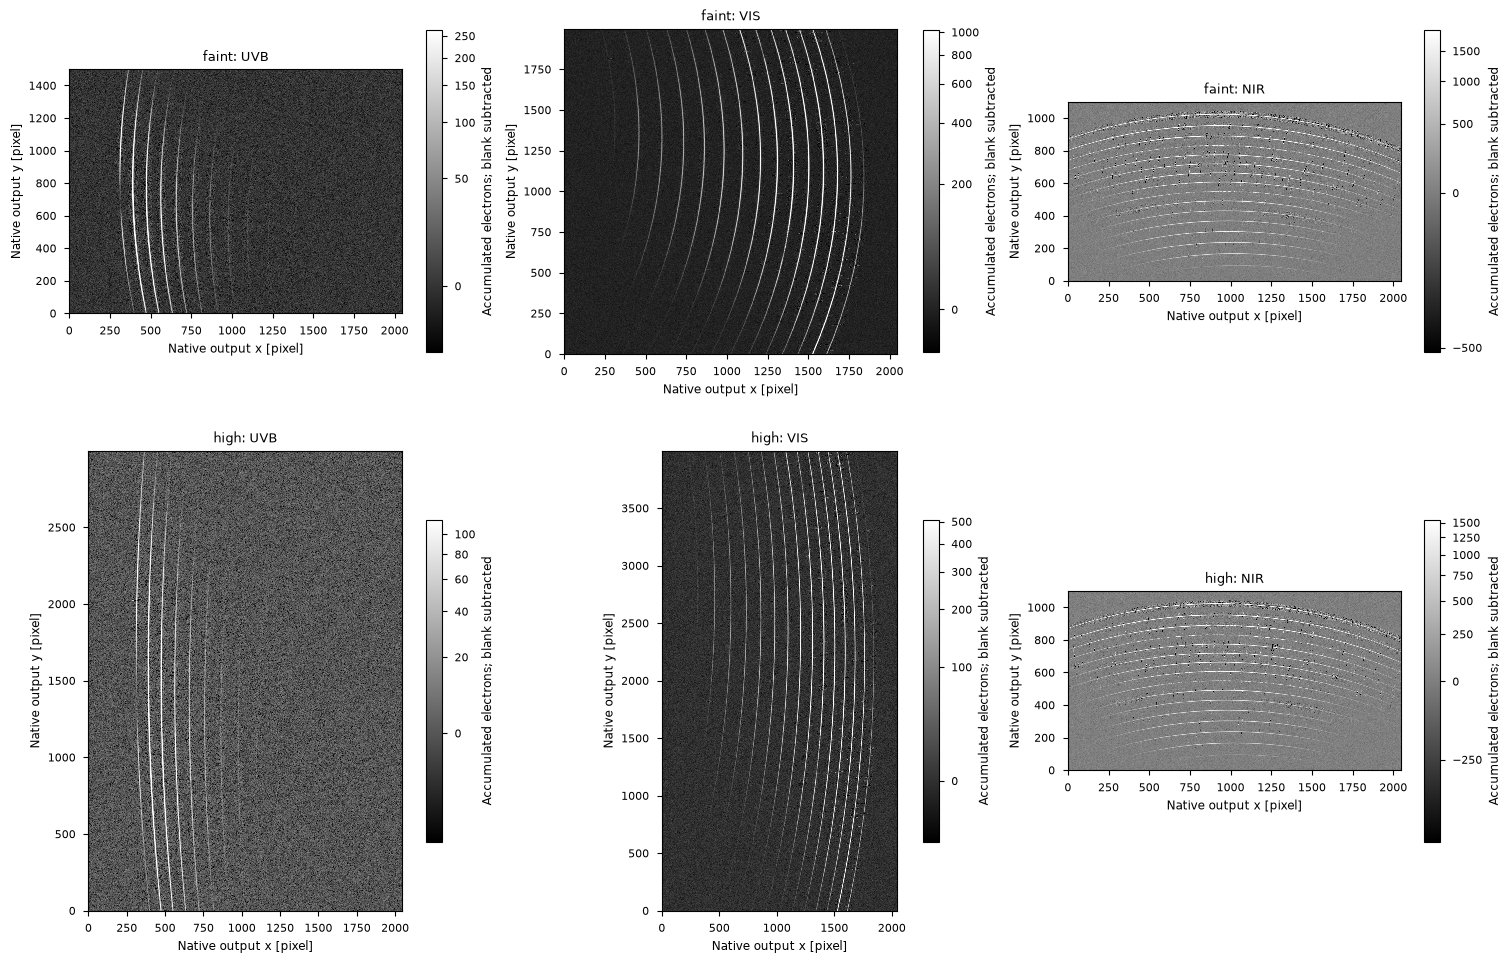

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10), layout='constrained')
for row, mode in enumerate(configurations):
    for ax, arm, path in zip(axes[row], ARMS, frame_files[mode]['science']['KILONOVA_1.5D'], strict=True):
        with fits.open(path) as hdul:
            data = hdul[1].data
            image = ax.imshow(data, origin='lower', cmap='gray', norm=simple_norm(data, stretch='asinh', percent=99.5), interpolation='nearest')
            ax.set(title=f'{mode}: {arm}', xlabel='Native output x [pixel]', ylabel='Native output y [pixel]')
            fig.colorbar(image, ax=ax, label='Accumulated electrons; blank subtracted', shrink=.7)
fig.savefig(output_dir/'native_frames.png', dpi=150)
plt.show()

## Extract, flux calibrate and stitch

The prototype DRP uses measured order traces, simulated lamp peaks and the configured X-shooter trace model for the model-assisted wavelength solution. The short illuminated flat separates traces; the full-slit flat supplies normalization. Each science input is one prepared sum with explicit variance, including its independent blank. Extraction propagates those pixel variances. Flux uncertainties are conditional on the fitted calibration response; standard/flat fitting uncertainty is a separate contribution.

Arc support differs between modes. Faint-mode UVB orders 13–21, VIS orders 26/30 and NIR order 26 have no accepted isolated lines and use the configured model plus the arm-wide pixel correction. Higher resolution supplies accepted lines in every UVB/VIS order; NIR order 26 still relies on the model. The number of fitted per-order corrections depends on the accepted line count. See the [calibration assessment](../../zshooter-drp/docs/source/xshooter-reduction.md) for line counts and residuals; a low fitted-line RMS is not an independent wavelength measurement in an unsupported order.

NIR has no additive bias in this configured model; its matching blank removes dark and thermal counts. No NIR bias group is passed to the DRP, whose generic missing-bias warning is expected here. A zero-second NIR read is outside the effective-noise table and is not used to manufacture a zero-noise calibration. The CCD biases do have zero exposure; their file-count scaling warning refers to subtracting one bias per calibration exposure, not missing science exposure metadata.

Trace-save warnings reflect the validator's ascending-row convention. These products retain physical-order indexing, with wavelength and calibration rows checked against the saved order IDs; a decreasing row position does not indicate that the wavelength rows have been interchanged.

The reduction runs one arm at a time to bound memory. It saves native extracted orders, arm spectra and stitched products. Telluric bands and low-throughput order edges remain in the native products.

In [9]:
import logging
set_scopesim_log_level('warning')
logging.disable(logging.INFO)
import pyreduce
from pyreduce.spectra import Spectra
from zsdrp.XSHOOTER import XSHOOTER
from zsdrp.pipe import run_reduction, run_flux_calibration_and_stitch
from zsdrp.steps import splice

print('PyReduce:', pyreduce.__file__)
reference = ab_spectrum(mag=16)
reference_wave = reference.waveset
reference_flux = convert_flux(reference_wave, reference(reference_wave), 'FLAM')

def stitch_arm_files(paths, destination):
    arms = [Spectra.read(path, raw=True) for path in paths]
    combined = Spectra(data=[arm.data[0] for arm in arms], header=arms[0].header)
    stitched = splice(combined, simple=True)
    stitched.save(destination)

arm_products, stitched_products = {}, {}
for mode in configurations:
    directory = output_dir/mode
    arm_products[mode], stitched_products[mode] = {}, {}
    for index, arm in enumerate(ARMS):
        armdir = directory/'reduced'/arm
        armdir.mkdir(parents=True, exist_ok=True)
        cals = frame_files[mode]['calibrations']
        controls = [frame_files[mode]['science'][name][index] for name in ('STANDARD', 'FLAT_AB')]
        files = {arm: {'bias': [cals['bias'][index]] if arm != 'NIR' else [], 'flat': [cals['flat'][index]], 'trace': [cals['trace'][index]], 'wavecal_master': [cals['arc'][index]], 'science': controls}}
        started = perf_counter()
        reduced = run_reduction(files, channels=[arm], output_dir=armdir, instrument=XSHOOTER(), trace_list=trains[mode]['spectral_traces'], lamp_lines=lamp_lines, require_variance=True, reuse_cals=False, disable_steps=['mask'], print_params=False, disable_all_plots=True)
        # Preserve counts before response calibration divides the standard by its exposure time.
        reduced[arm]['spectra']['STANDARD'].save(armdir/'standard_blazecal_counts.fits')
        calibrated = run_flux_calibration_and_stitch(reduced, reference_wave=reference_wave, reference_flux=reference_flux, standard_star_name='STANDARD', plot=False, output_dir=armdir)
        arm_products[mode][arm] = {'FLAT_AB': armdir/f'spectra_FLAT_AB_{arm}_fluxcal.fits'}
        timings.append((mode, f'calibrations and AB control {arm}', perf_counter()-started))
        print(mode, arm, f'control reduction {timings[-1][2]:.1f} s', flush=True)
        del reduced, calibrated
        gc.collect()
    filename = directory/'reduced'/'FLAT_AB_stitched.fits'
    stitch_arm_files([arm_products[mode][arm]['FLAT_AB'] for arm in ARMS], filename)
    stitched_products[mode]['FLAT_AB'] = filename
pd.DataFrame(timings, columns=['mode', 'stage', 'seconds']).to_csv(output_dir/'timings.csv', index=False)

py.warnings - WARNING: /Users/jibailey/src/PyReduce-xshooter/pyreduce/combine_frames.py:15: DeprecationWarning: Please import `median_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import median_filter

py.warnings - WARNING: /Users/jibailey/src/PyReduce-xshooter/pyreduce/util.py:17: DeprecationWarning: Please import `median_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import median_filter

py.warnings - WARNING: /Users/jibailey/src/PyReduce-xshooter/pyreduce/trace.py:29: DeprecationWarning: Please import `gaussian_filter1d` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import gaussian_filter1d, median_filter, uniform_filter1d

py.warnings - WARNING: /Use

Trace: 100%|██████████| 12/12 [00:02<00:00,  5.55it/s]


WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
simple_wavesol: 11/11 lines, channel +0.020 -0.025 x/nx px, rms 0.030 px
WARNING - Traces not ordered by y-position at x=988: trace 1 (y=1360.2) < trace 0 (y=1505.8) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=988: trace 1 (y=1360.2) < trace 0 (y=1505.8) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
WARNING - Traces not ordered by y-position at x=988: trace 2 (y=1223.8) < trace 1 (y=1360.2) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=988: trace 2 (y=1223.8) < trace 1 (y=1360.2

Trace: 100%|██████████| 15/15 [00:04<00:00,  3.56it/s]


WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
simple_wavesol: 58/58 lines, channel +0.023 -0.013 x/nx px, rms 0.029 px
WARNING - Traces not ordered by y-position at x=1457: trace 1 (y=1589.2) < trace 0 (y=1736.0) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/VIS/trace_VIS.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1457: trace 1 (y=1589.2) < trace 0 (y=1736.0) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/VIS/trace_VIS.fits
WARNING - Traces not ordered by y-position at x=1457: trace 2 (y=1450.0) < trace 1 (y=1589.2) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/VIS/trace_VIS.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1457: trace 2 (y=1450.0) < trace 1 (y=15

...

WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
simple_wavesol: 82/83 lines, channel -0.012 +0.047 x/nx px, rms 0.059 px
WARNING - Traces not ordered by y-position at x=1965: trace 1 (y=1360.3) < trace 0 (y=1506.1) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/high/reduced/UVB/trace_UVB.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1965: trace 1 (y=1360.3) < trace 0 (y=1506.1) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/high/reduced/UVB/trace_UVB.fits
WARNING - Traces not ordered by y-position at x=1965: trace 2 (y=1223.9) < trace 1 (y=1360.3) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/high/reduced/UVB/trace_UVB.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1965: trace 2 (y=1223.9) < trace 1 (y=1360.

Trace: 100%|██████████| 15/15 [00:04<00:00,  3.15it/s]


WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
simple_wavesol: 190/197 lines, channel +0.023 +0.007 x/nx px, rms 0.076 px
WARNING - Traces not ordered by y-position at x=2920: trace 1 (y=1589.3) < trace 0 (y=1736.1) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/high/reduced/VIS/trace_VIS.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=2920: trace 1 (y=1589.3) < trace 0 (y=1736.1) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/high/reduced/VIS/trace_VIS.fits
WARNING - Traces not ordered by y-position at x=2920: trace 2 (y=1450.1) < trace 1 (y=1589.3) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/high/reduced/VIS/trace_VIS.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=2920: trace 2 (y=1450.1) < trace 1 (y=158

Trace: 100%|██████████| 16/16 [00:04<00:00,  3.42it/s]


simple_wavesol: 124/127 lines, channel +0.015 -0.014 x/nx px, rms 0.054 px
WARNING - Traces not ordered by y-position at x=1024: trace 1 (y=951.6) < trace 0 (y=1022.0) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/high/reduced/NIR/trace_NIR.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1024: trace 1 (y=951.6) < trace 0 (y=1022.0) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/high/reduced/NIR/trace_NIR.fits
WARNING - Traces not ordered by y-position at x=1024: trace 2 (y=888.3) < trace 1 (y=951.6) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/high/reduced/NIR/trace_NIR.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1024: trace 2 (y=888.3) < trace 1 (y=951.6) when saving to /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/high/reduced/NIR/trace_NIR.fits
WARNING - Traces not ordered by y-position at x=102

## Flat AB recovery and the extracted kilonova scenes

The flat AB control tests the flux scale without host light or transient color. Its finite wavelength-bin uncertainties use the propagated sparse spectral covariance, including extraction and rebinning correlations. The integration-bin spacing below is a display and measurement choice, not a new measured resolving power.

The smooth sensitivity fit calibrates the continuum; this prototype does not apply a telluric correction. Selected comparison windows still contain atmospheric lines and response-fit residuals. The correlated excursions visible in the flat-AB plot should not all be assigned to random detector noise, even when the whole-arm integral is consistent with unity.

The kilonova extractions contain both transient and transmitted host light. The black reference curves show the input transient alone, so scene/reference offsets are not a photon-conservation test. The plotted uncertainties describe the detector fluctuations conditional on these fitted traces, wavelength solutions and response calibration; independent calibration realizations are a separate uncertainty source.

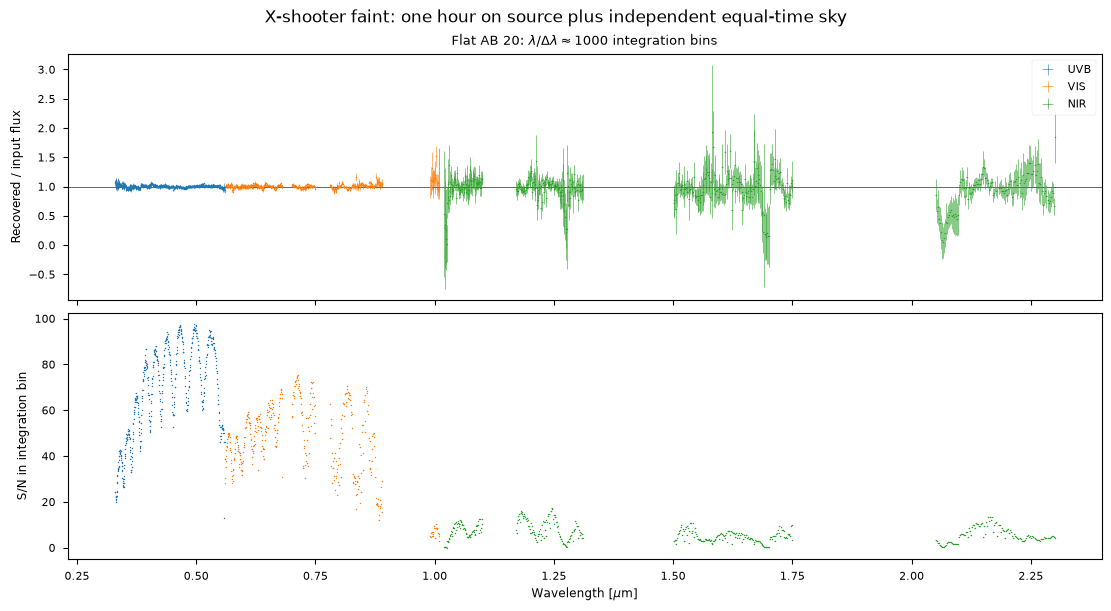

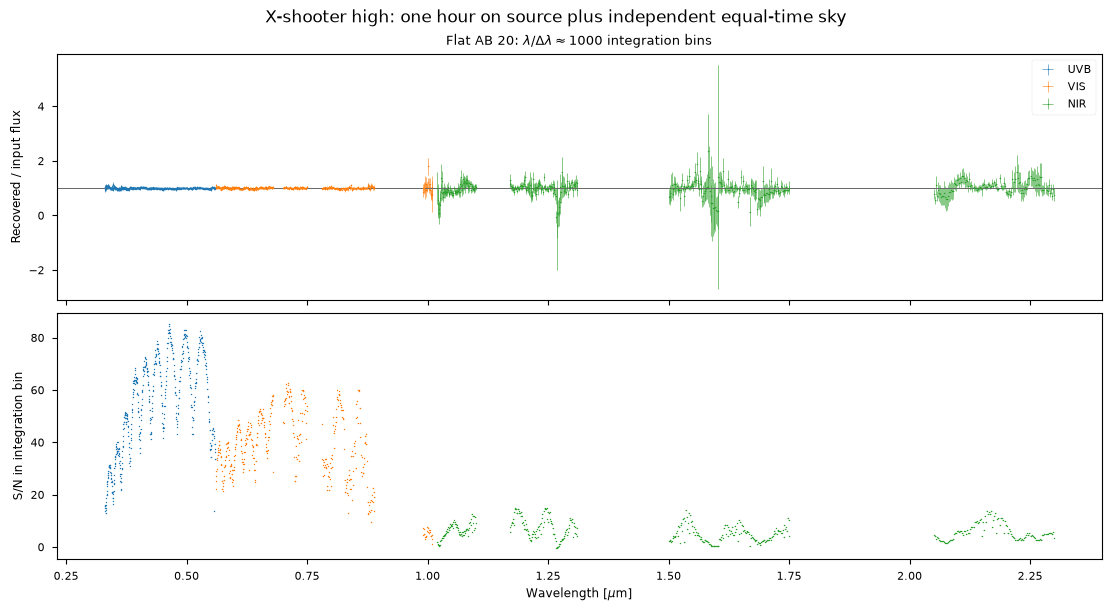

mode,arm,covered_width,ratio,ratio_uncertainty,snr
,,Angstrom,,,
str5,str3,float64,float64,float64,float64
faint,UVB,2300.0,1.0031,0.0016,623.5
faint,VIS,3000.0,1.0072,0.0041,244.9
faint,NIR,7200.0,0.9570,0.0317,30.1
high,UVB,2300.0,1.0020,0.0022,458.2
high,VIS,3000.0,1.0068,0.0045,226.2
high,NIR,7197.8,0.9774,0.0395,24.7


In [10]:
from astropy.table import vstack
from zs_scopesim_tools.reduction_checks import flat_ab_extraction_bins, flat_ab_band_integrals

# Fixed windows avoid the deep atmospheric bands; native FITS products retain all coverage.
retained = {
    'UVB': [(.33*u.um, .56*u.um)],
    'VIS': [(.56*u.um, .68*u.um), (.70*u.um, .75*u.um), (.78*u.um, .89*u.um), (.99*u.um, 1.01*u.um)],
    'NIR': [(1.02*u.um, 1.10*u.um), (1.17*u.um, 1.31*u.um), (1.50*u.um, 1.75*u.um), (2.05*u.um, 2.30*u.um)],
}
# These exceed the largest native spacings: .368/.427/1.180 Angstrom in faint mode.
max_gap = {'UVB': .5*u.AA, 'VIS': .5*u.AA, 'NIR': 1.5*u.AA}
flat_ab_bins, band_tables = {}, []
for mode in configurations:
    files = {arm: arm_products[mode][arm]['FLAT_AB'] for arm in ARMS}
    bins, figure = flat_ab_extraction_bins(files, intervals=retained, max_gap=max_gap, magnitude=20., bin_R=1000.)
    flat_ab_bins[mode] = bins
    bins.write(output_dir/mode/'flat_ab_bins.ecsv', overwrite=True)
    figure.suptitle(f'X-shooter {mode}: one hour on source plus independent equal-time sky')
    figure.savefig(output_dir/mode/'flat_ab_recovery.png', dpi=180)
    plt.show()
    bands = flat_ab_band_integrals(files, intervals=retained, max_gap=max_gap, magnitude=20.)
    bands['mode'] = mode
    band_tables.append(bands)
closure = vstack(band_tables)
closure.write(output_dir/'flat_ab_closure.ecsv', overwrite=True)
for column in ('ratio', 'ratio_uncertainty'):
    closure[column].info.format = '.4f'
closure['covered_width'].info.format = '.1f'
closure['snr'].info.format = '.1f'
display(closure[['mode', 'arm', 'covered_width', 'ratio', 'ratio_uncertainty', 'snr']])

In [11]:
def reduce_phase(phase):
    object_name = f'KILONOVA_{phase:g}D'
    timings[:] = [row for row in timings if not row[1].startswith(object_name+' extraction ')]
    for mode in configurations:
        directory = output_dir/mode
        for index, arm in enumerate(ARMS):
            armdir = directory/'reduced'/arm
            cals = frame_files[mode]['calibrations']
            files = {arm: {'bias': [cals['bias'][index]] if arm != 'NIR' else [], 'flat': [cals['flat'][index]], 'trace': [cals['trace'][index]], 'wavecal_master': [cals['arc'][index]], 'science': [frame_files[mode]['science'][object_name][index]]}}
            started = perf_counter()
            # These are exactly the calibration products rebuilt above from this mode's frames.
            reduced = run_reduction(files, channels=[arm], output_dir=armdir, instrument=XSHOOTER(), trace_list=trains[mode]['spectral_traces'], lamp_lines=lamp_lines, require_variance=True, reuse_cals=True, disable_steps=['mask'], print_params=False, disable_all_plots=True)
            reduced[arm]['spectra']['STANDARD'] = Spectra.read(armdir/'standard_blazecal_counts.fits', raw=True)
            calibrated = run_flux_calibration_and_stitch(reduced, reference_wave=reference_wave, reference_flux=reference_flux, standard_star_name='STANDARD', plot=False, output_dir=armdir)
            arm_products[mode][arm][object_name] = armdir/f'spectra_{object_name}_{arm}_fluxcal.fits'
            timings.append((mode, f'{object_name} extraction {arm}', perf_counter()-started))
            print(mode, arm, object_name, f'reduction {timings[-1][2]:.1f} s', flush=True)
            del reduced, calibrated
            gc.collect()
        filename = directory/'reduced'/f'{object_name}_stitched.fits'
        stitch_arm_files([arm_products[mode][arm][object_name] for arm in ARMS], filename)
        stitched_products[mode][object_name] = filename
    pd.DataFrame(timings, columns=['mode', 'stage', 'seconds']).to_csv(output_dir/'timings.csv', index=False)

In [12]:
reduce_phase(1.5)

Running reduction for channel UVB...
WARNING - Traces not ordered by y-position at x=988: trace 1 (y=1360.2) < trace 0 (y=1505.8) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=988: trace 1 (y=1360.2) < trace 0 (y=1505.8) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
WARNING - Traces not ordered by y-position at x=988: trace 2 (y=1223.8) < trace 1 (y=1360.2) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=988: trace 2 (y=1223.8) < trace 1 (y=1360.2) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
WARNING - Traces not ordered by y-position at x=988: trace 3 (y=1096.1) < trace 2 (y=1223.8) lo

In [13]:
reduce_phase(7.5)

Running reduction for channel UVB...
WARNING - Traces not ordered by y-position at x=988: trace 1 (y=1360.2) < trace 0 (y=1505.8) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=988: trace 1 (y=1360.2) < trace 0 (y=1505.8) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
WARNING - Traces not ordered by y-position at x=988: trace 2 (y=1223.8) < trace 1 (y=1360.2) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=988: trace 2 (y=1223.8) < trace 1 (y=1360.2) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
WARNING - Traces not ordered by y-position at x=988: trace 3 (y=1096.1) < trace 2 (y=1223.8) lo

In [14]:
reduce_phase(20.)

Running reduction for channel UVB...
WARNING - Traces not ordered by y-position at x=988: trace 1 (y=1360.2) < trace 0 (y=1505.8) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=988: trace 1 (y=1360.2) < trace 0 (y=1505.8) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
WARNING - Traces not ordered by y-position at x=988: trace 2 (y=1223.8) < trace 1 (y=1360.2) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=988: trace 2 (y=1223.8) < trace 1 (y=1360.2) loaded from /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced/faint/reduced/UVB/trace_UVB.fits
WARNING - Traces not ordered by y-position at x=988: trace 3 (y=1096.1) < trace 2 (y=1223.8) lo

## Native extracted scenes

These plots retain native wavelength samples and show the extracted scene with its one-sigma uncertainty. No smoothing or common-resolution convolution is applied. The covariance is a local first-order propagation through the fitted extraction and resampling, conditional on the calibration products; it is not a full nonlinear uncertainty distribution.

At 20 days, weak UVB/VIS fits can have signed spatial profiles dominated by noise. Their numerical convergence does not make individual excursions physical detections. The extracted scene includes transmitted host light, whereas the black curve contains only the input transient. A scene/reference offset therefore needs that distinction before it can be interpreted.

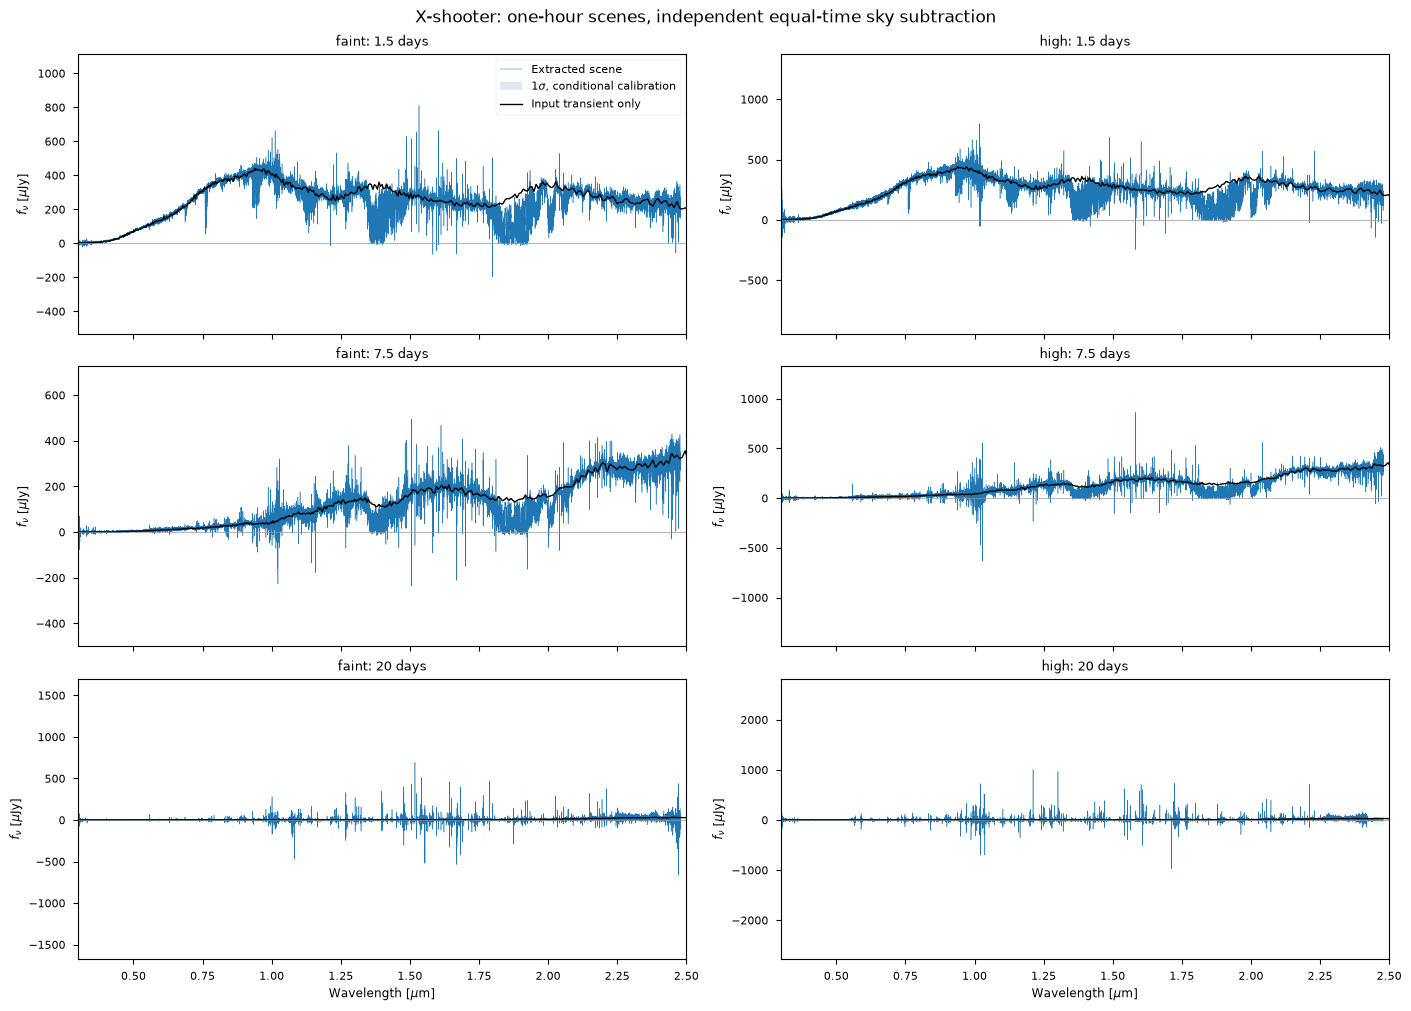

In [15]:
flux_unit = u.erg/(u.s*u.cm**2*u.AA)
model_wave = np.geomspace(.30, 2.50, 3000)*u.um
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True, constrained_layout=True)
for column, mode in enumerate(configurations):
    for row, phase in enumerate(phases):
        ax = axes[row, column]
        extracted_spectrum, = Spectra.read(stitched_products[mode][f'KILONOVA_{phase:g}D'], raw=True).data
        wave = extracted_spectrum.wave*u.AA
        scale = (1*flux_unit).to_value(u.uJy, equivalencies=u.spectral_density(wave))
        flux = extracted_spectrum.spec*scale
        uncertainty = extracted_spectrum.sig*scale
        ax.plot(wave.to_value(u.um), flux, lw=.35, color='C0', label='Extracted scene')
        ax.fill_between(wave.to_value(u.um), flux-uncertainty, flux+uncertainty, color='C0', alpha=.15, linewidth=0, label=r'$1\sigma$, conditional calibration')
        input_flux = convert_flux(model_wave, spectra[phase](model_wave), u.uJy)
        ax.plot(model_wave.value, input_flux.value, color='black', lw=1, label='Input transient only')
        ax.set(title=f'{mode}: {phase:g} days', ylabel=r'$f_\nu$ [$\mu$Jy]', xlim=(.30, 2.50))
        ax.axhline(0, color='0.6', lw=.5)
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel(r'Wavelength [$\mu$m]')
fig.suptitle('X-shooter: one-hour scenes, independent equal-time sky subtraction')
fig.savefig(output_dir/'stitched_kilonovae.png', dpi=180)
plt.show()

### Kilonova epochs: X-shooter and ZShooter

Each mode below follows the ZShooter notebook's flux/S/N figure. Faint traces show the native X-shooter samples; solid epoch-colored curves use the same 51-sample median display filter as ZShooter. Burnt-red curves are the three saved ZShooter results, when present at the explicit filename template below with their adjacent trace/wavelength calibrations. S/N is computed before filtering; the filter does not put the instruments at a common resolving power.

The dashed grey flux curves are the [ENGRAVE AT2017gfo spectra](https://www.engrave-eso.org/AT2017gfo-Data-Release/) at release phases 1.43 and 7.40 days, from the observations published by [Pian et al. (2017)](https://doi.org/10.1038/nature24298) and [Smartt et al. (2017)](https://doi.org/10.1038/nature24303). Their published flux scale is retained. They have photometric and telluric corrections and release smoothing; Galactic extinction remains. No observed 20-day curve or inferred published S/N is added.

The observations used 1.0/0.9/0.9 arcsec slits, with 2400/3600 s exposures, seeing 0.61/0.53 arcsec and airmass ranges 1.45–1.72/1.66–2.44 at the two epochs ([Pian et al., Extended Data Table 2](https://arts.units.it/bitstream/11368/2921596/4/2921596_nature24298-PostPrint.pdf)). These are observational context for both simulated modes; equal slit widths do not imply identical detector settings or observing conditions. See the local [reference-data notes](reference_data/AT2017gfo/README.md) for the files and column conventions.

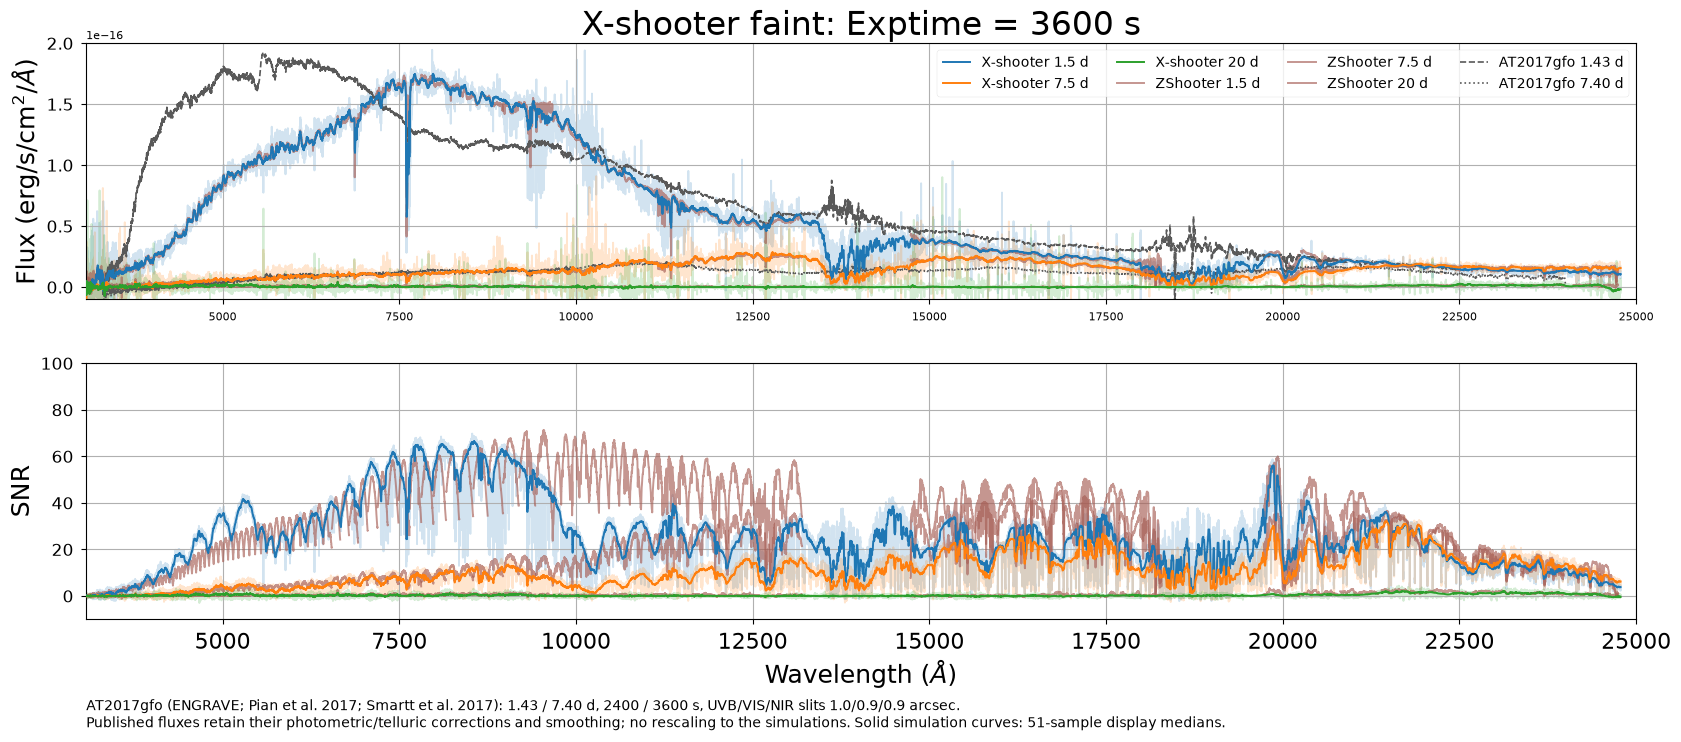

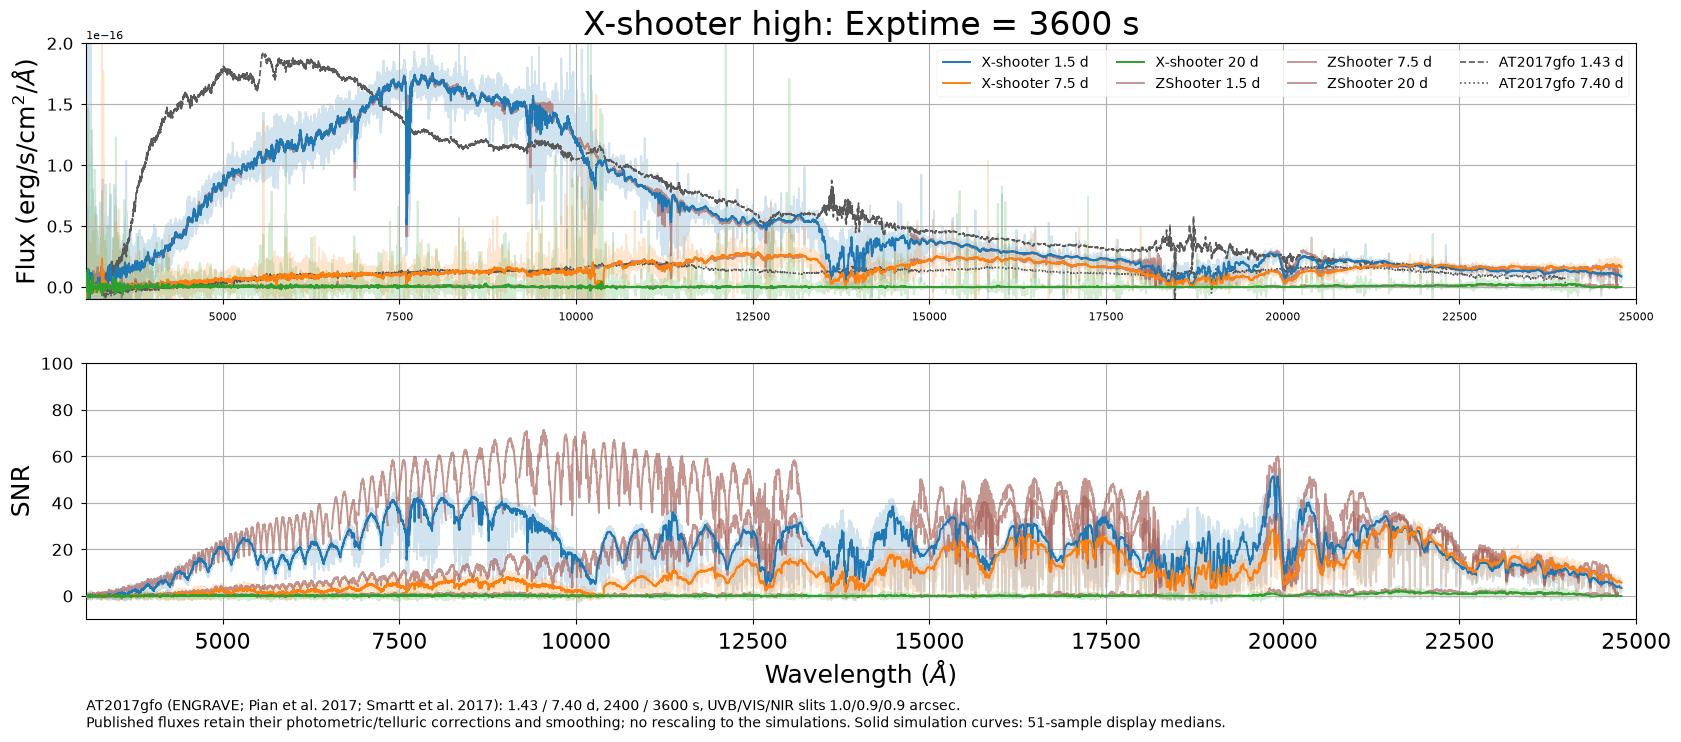

In [22]:
from scipy.ndimage import median_filter

zshooter_file = "01_Kilonovae/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/spectra_KN_{phase:.1f}D_SUB_stitched.txt"
zshooter_tables, zshooter_curves = {}, {}
for phase in phases:
    filename = Path(zshooter_file.format(phase=phase))
    if filename.exists():
        zshooter_tables[phase] = pd.read_csv(filename, sep='\t', comment='#')

zshooter_dir = Path(zshooter_file).parent
zshooter_channels = ('BLUE', 'GREEN', 'RED', 'YJ', 'H', 'K')
if zshooter_tables and all((zshooter_dir/f'trace_{channel}.fits').exists() and (zshooter_dir/f'wavecal_{channel}.npz').exists() for channel in zshooter_channels):
    zshooter_native_gap = {}
    for channel in zshooter_channels:
        with fits.open(zshooter_dir/f'trace_{channel}.fits') as trace_file, np.load(zshooter_dir/f'wavecal_{channel}.npz') as calibration:
            column_ranges = trace_file['TRACES'].data['COL_RANGE']
            native_steps = np.concatenate([np.diff(wave[start:end]) for wave, (start, end) in zip(calibration['wave_img'], column_ranges, strict=True)])
        zshooter_native_gap[channel] = np.max(np.abs(native_steps))*u.AA
    gap = max(zshooter_native_gap.values()).to_value(u.AA)
    for phase, table in zshooter_tables.items():
        wave, flux, uncertainty = table['wavelength'], table['flux'], table['eflux']
        snr = flux/uncertainty
        parts = np.split(np.arange(len(wave)), np.flatnonzero(np.diff(wave) > gap) + 1)
        zshooter_curves[phase] = [(wave[part], median_filter(flux[part], 51), median_filter(snr[part], 51)) for part in parts]

observed_curves = []
for observed_phase, mjd, style in ((1.43, 57983.969, '--'), (7.40, 57990.000, ':')):
    filename = Path('reference_data/AT2017gfo')/f'AT2017gfo_ENGRAVE_v1.0_XSHOOTER_MJD-{mjd:.3f}_Phase+{observed_phase:.2f}d.dat'
    observed_wave, observed_flux = np.loadtxt(filename, usecols=(0, 1), unpack=True)
    # The released tables start with zero-filled flux samples; retain negative measurements.
    observed_curves.append((observed_phase, observed_wave, np.ma.masked_equal(observed_flux, 0), style))

for mode in configurations:
    fig, ax = plt.subplots(2, 1, figsize=(20, 8))
    ax[0].grid(True)
    ax[1].grid(True)
    ax[0].tick_params(axis='y', labelsize=12)
    ax[1].tick_params(axis='y', labelsize=12)
    ax[1].tick_params(axis='x', labelsize=16)
    ax[0].set_ylabel(r'Flux (erg/s/cm$^2/\AA$)', fontsize=18)
    ax[1].set_ylabel('SNR', fontsize=18)
    ax[1].set_xlabel(r'Wavelength ($\AA$)', fontsize=18)

    for i, phase in enumerate(phases):
        product = Spectra.read(stitched_products[mode][f'KILONOVA_{phase:g}D'], raw=True)
        extracted_spectrum, = product.data
        wave, flux, uncertainty = extracted_spectrum.wave, extracted_spectrum.spec, extracted_spectrum.sig
        # FITS arrays are big-endian; ndimage requires native byte order, retaining double precision.
        flux = flux.astype(np.float64)
        snr = flux/uncertainty
        gap = max(max_gap.values()).to_value(u.AA)
        # Filter native S/N for display only, independently across coverage gaps.
        for part in np.split(np.arange(len(wave)), np.flatnonzero(np.diff(wave) > gap) + 1):
            ax[0].plot(wave[part], flux[part], alpha=.2, color=f'C{i}', zorder=1)
            ax[0].plot(wave[part], median_filter(flux[part], 51), color=f'C{i}', zorder=3, label=f'X-shooter {phase:g} d' if part[0] == 0 else None)
            ax[1].plot(wave[part], snr[part], alpha=.2, color=f'C{i}', zorder=1)
            ax[1].plot(wave[part], median_filter(snr[part], 51), color=f'C{i}', zorder=3)

    for phase, curves in zshooter_curves.items():
        for j, (wave, flux, snr) in enumerate(curves):
            ax[0].plot(wave, flux, color='#a65e55', alpha=.65, zorder=2, label=f'ZShooter {phase:g} d' if j == 0 else None)
            ax[1].plot(wave, snr, color='#a65e55', alpha=.65, zorder=2)
    for observed_phase, wave, flux, style in observed_curves:
        ax[0].plot(wave, flux, color='0.35', linestyle=style, lw=1.2, zorder=2.5, label=f'AT2017gfo {observed_phase:.2f} d')

    ax[0].set_title(f'X-shooter {mode}: Exptime = {product.header["EXPTIME"]:g} s', fontsize=24)
    ax[0].set_xlim(3070, 25000)
    ax[1].set_xlim(3070, 25000)
    ax[0].set_ylim(-.01e-15, .2e-15)
    ax[1].set_ylim(-10, 100)
    ax[0].legend(ncol=4, fontsize=10)
    fig.subplots_adjust(bottom=.16, hspace=.25)
    fig.text(.125, .025, 'AT2017gfo (ENGRAVE; Pian et al. 2017; Smartt et al. 2017): 1.43 / 7.40 d, 2400 / 3600 s, UVB/VIS/NIR slits 1.0/0.9/0.9 arcsec.\nPublished fluxes retain their photometric/telluric corrections and smoothing; no rescaling to the simulations. Solid simulation curves: 51-sample display medians.', fontsize=10)
    fig.savefig(output_dir/f'kilonova_epochs_{mode}.png', dpi=160)
    plt.show()

## Runtime and interpretation

The timing table records optical `observe()` calls and complete per-arm DRP plus flux-calibration calls separately. Native readout, blank subtraction and FITS writing are additional work. The flat point-source observations take about 93–111 seconds here; the extended host plus kilonova observations take about 203–223 seconds. The two-minute observation target is therefore met for the technical control, but not for these extended scenes.

Each prepared science frame and its variance are saved beside the native ADU readouts. Arm and stitched FITS products retain the propagated spectral covariance; ASCII exports contain only diagonal uncertainties.

A fixed random seed makes this demonstration reproducible. Distinct readout IDs separate every object from its blank and the other objects. Corresponding IDs reuse that seed between the two modes, so the modes are not presented as independent noise ensembles; their individual variances remain the basis of the uncertainty calculations.

In [16]:
timing_table = pd.DataFrame(timings, columns=['mode', 'stage', 'seconds'])
timing_table.to_csv(output_dir/'timings.csv', index=False)
display(timing_table)
print('Products:', output_dir)

,mode,stage,seconds
0,faint,bias,56.899020
1,faint,arc,60.671193
2,faint,flat,60.181872
3,faint,trace,60.819779
4,faint,blank rates,122.875095
5,faint,STANDARD,123.656431
6,faint,FLAT_AB,126.206796
7,faint,KILONOVA_1.5D,237.423490
8,faint,KILONOVA_7.5D,236.063655
9,faint,KILONOVA_20D,313.703477


Products: /Users/jibailey/src/zs-scopesim/notebooks/xshooter_kilonova_reduced
